# Aprendizaje Automático I
## Práctica 3
Manuel Suano Gallardo

### Importación de librerías y definición de funciones generales

In [ ]:
import random
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import joblib

# Para el transformador personalizado
from sklearn.base import BaseEstimator, TransformerMixin

# Para el preprocesado
from category_encoders import BinaryEncoder
from sklearn.preprocessing import (
	OrdinalEncoder, KBinsDiscretizer, FunctionTransformer, RobustScaler, 
	StandardScaler
)
from sklearn.model_selection import train_test_split

# Para la construcción de pipelines
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import make_column_transformer

# Para los modelos
from sklearn.svm import SVC, LinearSVC, SVR, LinearSVR
from sklearn.model_selection import cross_val_score, GridSearchCV

from sklearn.metrics import (
	ConfusionMatrixDisplay, confusion_matrix, accuracy_score, mean_absolute_percentage_error
)

Al igual que en la práctica anterior, defino esta función para resetear la semilla de la pseudoaleatoriedad y poder tener reproducibilidad de los resultados

In [ ]:
def resetear_semilla():
	random.seed(0)
	np.random.seed(0)
	# tf.random.set_seed(0) 

### 
---

### Datos para la práctica

En esta práctica se usan los mismos datos que se usaron en la Práctica 1. El análisis en general de estos es el mismo que se hizo en dicha práctica, por lo que se va a omitir.

In [ ]:
dataset_org = pd.read_csv('./airbnb.csv', sep=',')

# Al igual que en la práctica 1, voy a traducir los nombres de las columnas al 
# español. No es esencial, pero me resulta más cómodo.
traduccion_ing_2_esp = {
	'neighbourhood_group' 			: 'distrito',
	'neighbourhood'					: 'barrio',
	'latitude'						: 'latitud',
	'longitude'						: 'longitud',
	'room_type'						: 'tipo_habitacion',
	'price'							: 'precio',
	'minimum_nights'				: 'minimo_noches',
	'number_of_reviews'				: 'numero_opiniones',
	'reviews_per_month'				: 'opiniones_mes',
	'calculated_host_listings_count': 'numero_propiedades_host',
	'availability_365'				: 'disponibilidad_anual'
}

dataset = dataset_org.rename(columns=traduccion_ing_2_esp)

Para ambos problemas expuestos en la práctica se puede usar la misma división de datos. En la Práctica 1 se realizó la separación teniendo en cuenta el barrio, pues existía un barrio para el que sólo una instancia lo tenía como valor en la característica. Realizaremos el mismo procedimiento para separar los conjuntos:
1. Codificación de la característica `barrio` usando `OrdinalEncoder`.
2. Extracción de la instancia con el barrio 'El Pardo'. 
3. División del conjunto de datos en entrenamiento y test según la codificación de la característica `barrio`.
4. Adición en el conjunto de entrenamiento de la instancia extraída en el paso 2. Se añade de forma manual debido a que al indicar la nueva característica creada en el paso 1 en el parámetro `stratify` en `train_test_split`, al haber solo una ocurrencia de 'El Pardo', se produce error.
5. Eliminación de la nueva característica añadida en el paso 1.

In [ ]:
# Paso 1
condificador = OrdinalEncoder()
dataset[['cat_barrio']] = condificador.fit_transform(dataset[['barrio']])

# Paso 2
barrio_El_Pardo = dataset[dataset['barrio'] == 'El Pardo']
dataset_sin_el_pardo = dataset.drop(barrio_El_Pardo.index.to_numpy())

# Paso 3
dataset_train, dataset_test = train_test_split(
	dataset_sin_el_pardo, 
	test_size=0.2, 
	stratify=dataset_sin_el_pardo["cat_barrio"], 
	random_state=0
)

# Paso 4
dataset_train = pd.concat([dataset_train, barrio_El_Pardo])

# Paso 5
dataset_train = dataset_train.drop(['cat_barrio'], axis=1)
dataset_test = dataset_test.drop(['cat_barrio'], axis=1)

dataset_train.to_csv('datos_train.csv', sep=';')
dataset_test.to_csv('datos_test.csv', sep=';')

In [ ]:
# Este paso extra para obtener la misma separación, pues aún indicando el random
# state se realiza una separación diferente al no haberse ejecutado la función
# resetear_semilla con anterioridad

dataset_train = pd.read_csv('datos_train.csv', sep=';')
dataset_test = pd.read_csv('datos_test.csv', sep=';')

###
---

### Problema de Clasificación

#### Datos y preprocesamiento

En este primer apartado se va a realizar el mismo procesamiento que se realizó en la Práctica 1:
- Codificación ordinal para `tipo_habitación`. Donde están codificadas las clases a predecir.
- Codificación binaria para `distrito` y `barrio` debido al alto número de clases diferentes.
- Transformación a coordenadas cartesianas de `latitud` y `longitud`.
- _Bucketizing_ usando los cuartiles para `disponibilidad_anual`.
- Transformación usando la raíz cuadrada (no se puede usar el $\log$ pues existen instancias con valor 0) y escalado usando un escalador robusto (los datos no siguen una distribución normal) para `numero_opiniones` y `opiniones_mes`.
- Transformación usando el logaritmo y, de nuevo, un escalado robusto para `minimo_noches` y `numero_propiedades_host` debido a la distribución de los datos.
- Transformación logarítmica y escalado estándar para `precio`.

In [ ]:
tipo_habitacion_columna = ['tipo_habitacion']

habitacion_pipeline = make_pipeline(
	OrdinalEncoder()
)

In [ ]:
org_territorial_columnas = ['distrito', 'barrio']

org_territorial_pipeline = make_pipeline(
	BinaryEncoder()
)

In [ ]:
coordenadas_columnas = ['latitud', 'longitud']

class TransformadorCoordenadas(BaseEstimator, TransformerMixin):
	# def __init__(self):

	def transform(self, X : pd.DataFrame):
		'''
		Se tomará como primera columna la latitud y la segunda columna la longitud
		'''
		if isinstance(X, pd.DataFrame):
			X = X.to_numpy()
		
		dimensiones = X.shape
		if dimensiones[1] != 2:
			raise ValueError('Los datos no disponen de dos columnas')

		# Matriz para las coordenadas x, y, z
		coordenadas_transformadas = np.ndarray(shape=(dimensiones[0], 3), dtype=float)

		for fila in range(0, dimensiones[0]):
			coordenadas_transformadas[fila] = [
				np.cos(np.deg2rad(X[fila, 0])) * np.cos(np.deg2rad(X[fila, 1])),
				np.cos(np.deg2rad(X[fila, 0])) * np.sin(np.deg2rad(X[fila, 1])),
				np.sin(np.deg2rad(X[fila, 0]))
			]
		
		return coordenadas_transformadas

	def fit(self, X, y=None):
		'''
		No hace nada porque la transformación se realiza utilizando un algoritmo
		que no requiere de datos anteriores
		'''
		return self


	def get_feature_names_out(self, names=None):
		return ['x', 'y', 'z']

coordenadas_pipeline = make_pipeline(
	TransformadorCoordenadas()
)

In [ ]:
disponibilidad_columnas = ['disponibilidad_anual']

disponibilidad_pipeline = make_pipeline(
	KBinsDiscretizer(n_bins = 4, encode='onehot-dense', strategy='quantile', 
				  quantile_method='linear', random_state=0)
)

In [ ]:
opiniones_columnas = ['numero_opiniones', 'opiniones_mes']

opiniones_pipeline = make_pipeline(
	FunctionTransformer(np.sqrt, feature_names_out="one-to-one"),
	RobustScaler()
)

In [ ]:
log_columnas = ['minimo_noches', 'numero_propiedades_host']

log_pipeline = make_pipeline(
	FunctionTransformer(np.log, feature_names_out="one-to-one"),
	RobustScaler()
)

In [ ]:
precio_columna = ['precio']

precio_pipeline = make_pipeline(
	FunctionTransformer(np.log, feature_names_out="one-to-one"),
	StandardScaler()
)

Se definen las tuplas del pipeline junto con las columnas a las que afecta

In [13]:
transformador_habitacion 		= (habitacion_pipeline, tipo_habitacion_columna)
transformador_barrio_distrito 	= (org_territorial_pipeline, org_territorial_columnas)
transformador_coordenadas 		= (coordenadas_pipeline, coordenadas_columnas)
transformador_disponibilidad 	= (disponibilidad_pipeline, disponibilidad_columnas)
transformador_opiniones 		= (opiniones_pipeline, opiniones_columnas)
transformador_log 				= (log_pipeline, log_columnas)
transformador_precio 			= (precio_pipeline, precio_columna)

Se genera el pipeline completo para los datos de entrada y los de salida

In [ ]:
# Pipeline completo

# Para los datos de entrada
preprocesamiento = make_column_transformer(
	transformador_barrio_distrito,
	transformador_coordenadas,
	transformador_precio,
	transformador_opiniones,
	transformador_log,
	transformador_disponibilidad,
	# Para mantener los nombres de las características
	verbose_feature_names_out=False
)

# Para los datos de salida
preprocesamiento_target = make_column_transformer(
	transformador_habitacion,
	# Para mantener el nombre de la característica
	verbose_feature_names_out=False
)

Con el pipeline definido se puede ajustar los escaladores y transformar los datos de entrada

In [246]:
dataset_procesado = preprocesamiento.fit_transform(dataset_train)
x_train = pd.DataFrame(data=dataset_procesado, columns=preprocesamiento.get_feature_names_out())

dataset_procesado = preprocesamiento_target.fit_transform(dataset_train)
y_train = pd.DataFrame(data=dataset_procesado, columns=preprocesamiento_target.get_feature_names_out())

Definimos la misma función que estaba hecha en la Práctica 1 para la aplicación de este preprocesamiento.

In [ ]:
def generar_x_y(datos):
	'''
	Divide los datos en los conjuntos X e Y, ya preprocesados, para su uso en los
	modelos.
	'''
	x = pd.DataFrame(
		data = preprocesamiento.transform(datos), 
		columns = preprocesamiento.get_feature_names_out()
	)

	y = pd.DataFrame(
		data = preprocesamiento_target.transform(datos), 
		columns = preprocesamiento_target.get_feature_names_out()
	)

	return x,y

Con esta función podemos generar directamente los datos de test.

In [247]:
x_test, y_test = generar_x_y(dataset_test)

c:\Users\mansu\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


#### Validación y entrenamiento de los modelos

Comenzando por el modelo SVC. Creamos el modelo y ejecutamos cross-validation con los datos de entrenamiento. Se dejan todos los parámetros por defecto, a excepción de `random_state` para poder hacer la comparación de los modelos bajo las mismas condiciones.

In [ ]:
resetear_semilla()

modelo_svc = SVC(random_state=0)

cross_val_svc = cross_val_score(
	modelo_svc, x_train, y_train.to_numpy().ravel(), cv=10, scoring='accuracy'
)

Ahora realizaremos lo mismo pero con el modelo LinearSVC. De igual forma, se dejan los parámetros por defecto a excepción de `random_state`.

In [ ]:
resetear_semilla()

modelo_linear_svc = LinearSVC(random_state=0)

cross_val_linear_svc = cross_val_score(
	modelo_linear_svc, x_train, y_train.to_numpy().ravel(), cv=10, scoring='accuracy'
)

Para el LinearSVC no se tiene que realizar la afinación de hiperparámetros, por lo que se entrenará directamente el modelo usando los parámetros por defecto y todos los datos de entrenamiento. Con el modelo entrenado se generará las predicciones para los datos de test y se calculará la exactitud de dichas predicciones.

In [20]:
resetear_semilla()

modelo_linear_svc = LinearSVC(random_state=0)

modelo_linear_svc.fit(x_train, y_train.to_numpy().ravel())

y_predicho_linear_svc = modelo_linear_svc.predict(x_test)

exactitud_linear_svc_test = accuracy_score(y_test, y_predicho_linear_svc)

In [44]:
# joblib.dump(modelo_linear_svc, 'modelo_lineal_svc.pkl')

['modelo_lineal_svc.pkl']

En el caso del modelo SVC sí que hay que realizar el afinado de los parámetros. Siguiendo la sección 3.2 de la publicación recomendada en la práctica (https://www.ee.columbia.edu/~sfchang/course/spr/papers/svm-practical-guide.pdf), se realizará una primera búsqueda general y, a partir de los resultados obtenidos, una segunda búsqueda más específica para afinar el valor de los hiperparámetros C y $\gamma$.

In [ ]:
resetear_semilla()

pipeline_svc = Pipeline([
	("svc", SVC(random_state=0))
])

min_exp_C = -5
max_exp_C = 10

min_exp_gamma = -10
max_exp_gamma = 3

parametros_svr = {
	# Se calcularán tantos valores como exponentes enteros haya entre min_exp_C y max_exp_C
	'svc__C' : np.logspace(
		start=min_exp_C, stop=max_exp_C, base=2, num=len(list(range(min_exp_C,max_exp_C+1)))
	),
	# Se calcularán tantos valores como exponentes enteros haya entre min_exp_C y max_exp_C
	'svc__gamma' : np.logspace(
		start=min_exp_gamma, stop=max_exp_gamma, base=2, num=len(list(range(min_exp_gamma,max_exp_gamma+1)))
	)
}

optimizacion_svr = GridSearchCV(
	pipeline_svc, 
	parametros_svr, 
	cv=10, 
	scoring="accuracy",
	n_jobs=6
)

optimizacion_svr.fit(x_train, y_train.to_numpy().ravel())

,estimator,Pipeline(step...om_state=0))])
,param_grid,"{'svc__C': array([3.125e...2, 1.024e+03]), 'svc__gamma': array([9.7656...8.000000e+00])}"
,scoring,'accuracy'
,n_jobs,6
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,np.float64(256.0)


A partir de la primera búsqueda, podemos comprobar cuales son los valores óptimos para C ($2^8$) y para $\gamma$ ($2^{-6}$). Con estos valores realizaremos una segunda búsqueda en un intervalo más pequeño y que contenga más valores. Esta nueva búsqueda se hará incrementando y decrementando en 3 a partir del valor óptimo y seleccionando 15 elementos de ese intervalo.

In [21]:
optimizacion_svr.best_params_

{'svc__C': np.float64(256.0), 'svc__gamma': np.float64(0.015625)}

In [ ]:
resetear_semilla()

pipeline_svc = Pipeline([
	("svc", SVC(random_state=0))
])

mejor_exp_C = 8
var_exp_C = 3

mejor_exp_gamma = -6
var_exp_gamma = 3

parametros_svr = {
	'svc__C' : np.logspace(
		start=(mejor_exp_C - var_exp_C), stop=(mejor_exp_C + var_exp_C), base=2, num=15
	),
	'svc__gamma' : np.logspace(
		start=(mejor_exp_gamma - var_exp_gamma), stop=(mejor_exp_gamma + var_exp_gamma), base=2, num=15
	)
}

optimizacion_SVC_segunda = GridSearchCV(
	pipeline_svc, 
	parametros_svr, 
	cv=10, 
	scoring="accuracy",
	n_jobs=6
)

optimizacion_SVC_segunda.fit(x_train, y_train.to_numpy().ravel())

,estimator,Pipeline(step...om_state=0))])
,param_grid,"{'svc__C': array([ 32. ...048. ]), 'svc__gamma': array([0.0019..., 0.125 ])}"
,scoring,'accuracy'
,n_jobs,6
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,np.float64(256.0)


Tras hacer las segunda búsqueda, los mejores valores vuelven a ser los encontrados en la primera búsqueda.

In [24]:
optimizacion_SVC_segunda.best_params_

{'svc__C': np.float64(256.0), 'svc__gamma': np.float64(0.015625)}

In [43]:
# joblib.dump(optimizacion_SVC_segunda.best_estimator_, 'modelo_svc.pkl')
# mejor_modelo_svc = joblib.load('modelo_svc.pkl')

['modelo_svc.pkl']

Por lo que generamos la exactitud sobre los datos de test usando este modelo.

In [31]:
y_predicho_svc = optimizacion_SVC_segunda.best_estimator_.predict(x_test)

exactitud_svc_test = accuracy_score(y_test, y_predicho_svc)

###
---

### Problema de Regresión

#### Datos y preprocesamiento

El preprocesado de los datos, en términos de transformaciones y escalado, será el mismo que se aplica en el caso del problema de clasificación. Sin embargo, como sugiere la práctica, realizaremos un nuevo análisis de las variables `precio`, `minimo_noches` y `numero_propiedades_host` sobre los datos de entrenamiento para comprobar si existen valores atípicos que puedan afectar al ajuste del modelo. 

La utilidad de los valores atípicos dependerá del problema al que nos estemos enfrentando. Existen problemas donde los valores atípicos son el interés del problema, como puede ser el caso de la detección de fraude. Sin embargo, en otros contextos, los valores atípicos son simplemente desviaciones que se salen del comportamiento de la variable sin tener una razón para dicha desviación, cómo podría darse en estos datos, donde un un propietario pusiera un precio a un alojamiento bastante alejado al precio que se supondría acorde a las condiciones. En casos como ese, entrenar los modelos con los valores atípicos haría que se ajustasen a datos poco comunes o que incluso no tendrían por qué darse.

En este caso, partimos de la visualización de los diagramas de caja de esas tres variables para comprobar mejor la distribución de los datos. Como se puede ver, las tres características disponen de muchos valores atípicos, aunque la gran mayoría de ellos se encuentran concentrados relativamente cerca del máximo no atípico, existen algunos que se alejan de forma considerable de esta agrupación.

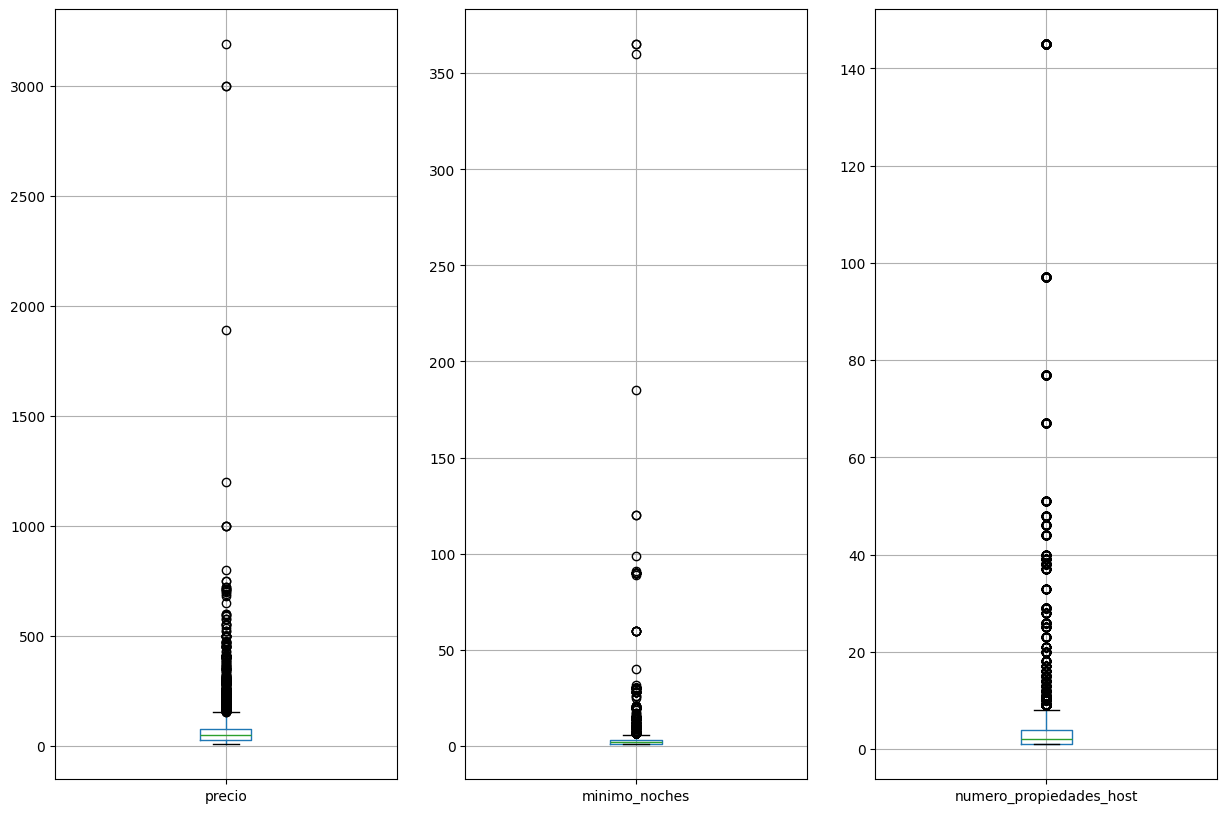

In [23]:
_, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 10))

dataset_train_3_variables = dataset_train[['precio', 'minimo_noches', 'numero_propiedades_host']]

dataset_train_3_variables.boxplot(column='precio', ax=axes[0])
dataset_train_3_variables.boxplot(column='minimo_noches', ax=axes[1])
dataset_train_3_variables.boxplot(column='numero_propiedades_host', ax=axes[2])

plt.show()

Seo (2006) propone varios métodos para detectar valores atípicos, entre los que se encuentra el z-score y el z-score modificado.

El z-score, $Z_i$, por su definición, puede verse alterado cuando se dispone de instancias con valores muy extremos, haciendo que no se detecten como valores atípicos. Es decir, que los valores menos extremos pasen desapercibidos por culpa de los valores más extremos, como ocurren en la Tabla 3 de Seo (2006). De forma normal, cuando se utiliza esta métrica, se indica como valor atípico aquellas instancias que tienen el $|Z_i|\geq 3$, aunque cuando se tienen distribuciones muy sesgadas esta métrica (si no se hace de forma recursiva) puede producir problemas cuando los tamaños de las muestras son pequeños (Osborne (2004)).

La alternativa al z-score es usar un z-score modificado, $M_i$ basado en la mediana de la desviación absoluta de la mediana. De esta forma, y como se puede ver en la Tabla 4 de Seo (2006), los valores atípicos quedan fuertemente identificados, a diferencia de lo que ocurre con el z-score, pues superan ampliamente el umbral de 3.5.

En los datos actuales no se dispone de pocos valores atípicos, pero si que existen valores atípicos muy agrupados cercano al $1.5\cdot IQR$, mientras que existen otros más extremos que pueden que sí hagan que los modelos se ajusten de manera errónea. Por ello, se comprobarán ambos métodos y se seleccionará aquel que se crea más conveniente, según la distribución resultante.

Empezando por el z-score, se puede ver que para `precio` existen 115 instancias de entrenamiento que superan el umbral de 3, para `minimo_noches` son 99 y para `numero_propiedades_host` son 316. Es decir, de las 10657 instancias que componen el conjunto de entrenamiento, como mucho un 4% (suponiendo que las intersecciones dos a dos entre las tres características sean nulas) contendrían valores atípicos.

In [ ]:
from scipy.stats import zscore

z_score_mayor = dataset_train_3_variables.apply(lambda lst : abs(zscore(lst)) >= 3)

for columna in z_score_mayor.columns:
	print(f'{columna}: {str(len(z_score_mayor[z_score_mayor[columna] == True]))}')

precio: 115
minimo_noches: 99
numero_propiedades_host: 316


Si no tenemos en cuenta las instancias que tienen algún valor atípico tenemos las siguientes gráficas.

(10138, 3)


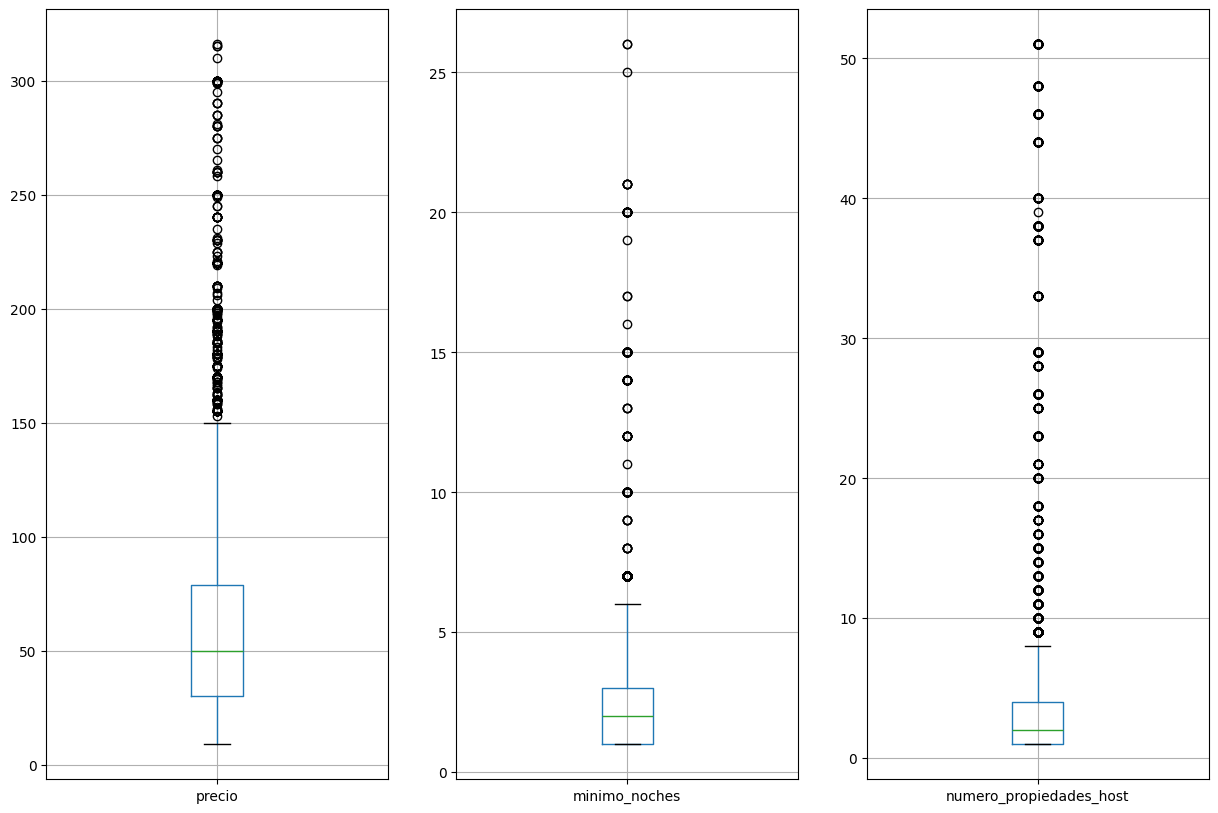

In [ ]:
dataset_train_3_variables_sin_atipicos = dataset_train_3_variables[
	(z_score_mayor['minimo_noches'] != True) & 
	(z_score_mayor['numero_propiedades_host'] != True) & 
	(z_score_mayor['precio'] != True)
]

_, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 10))

dataset_train_3_variables_sin_atipicos.boxplot(column='precio', ax=axes[0])
dataset_train_3_variables_sin_atipicos.boxplot(column='minimo_noches', ax=axes[1])
dataset_train_3_variables_sin_atipicos.boxplot(column='numero_propiedades_host', ax=axes[2])

print(dataset_train_3_variables_sin_atipicos.shape)

plt.show()

Las cuales, aunque siguen poseyendo un número considerable de valores, se encuentran más agrupados.

Pasando ahora al uso de la métrica del z-score modificado, se puede ver que el número de valores atípicos detectados es notablemente superior que en el caso anterior, con 469 para `precio`, 356 para `minimo_noches` y 1862 para `numero_propiedades_host`.

In [ ]:
def zscore_modif(list):
	mad = (abs(list - list.median())).median()
	return 0.6745 * ((list - list.median()) / mad)

z_score_modif_mayor = dataset_train_3_variables.apply(lambda lst : zscore_modif(lst) >= 3.5)

for columna in z_score_modif_mayor.columns:
	print(f'{columna}: {str(len(z_score_modif_mayor[z_score_modif_mayor[columna] == True]))}')

precio: 469
minimo_noches: 356
numero_propiedades_host: 1862


Las gráficas de caja eliminando las instancias con estos valores atípicos quedan tal que:

(8270, 3)


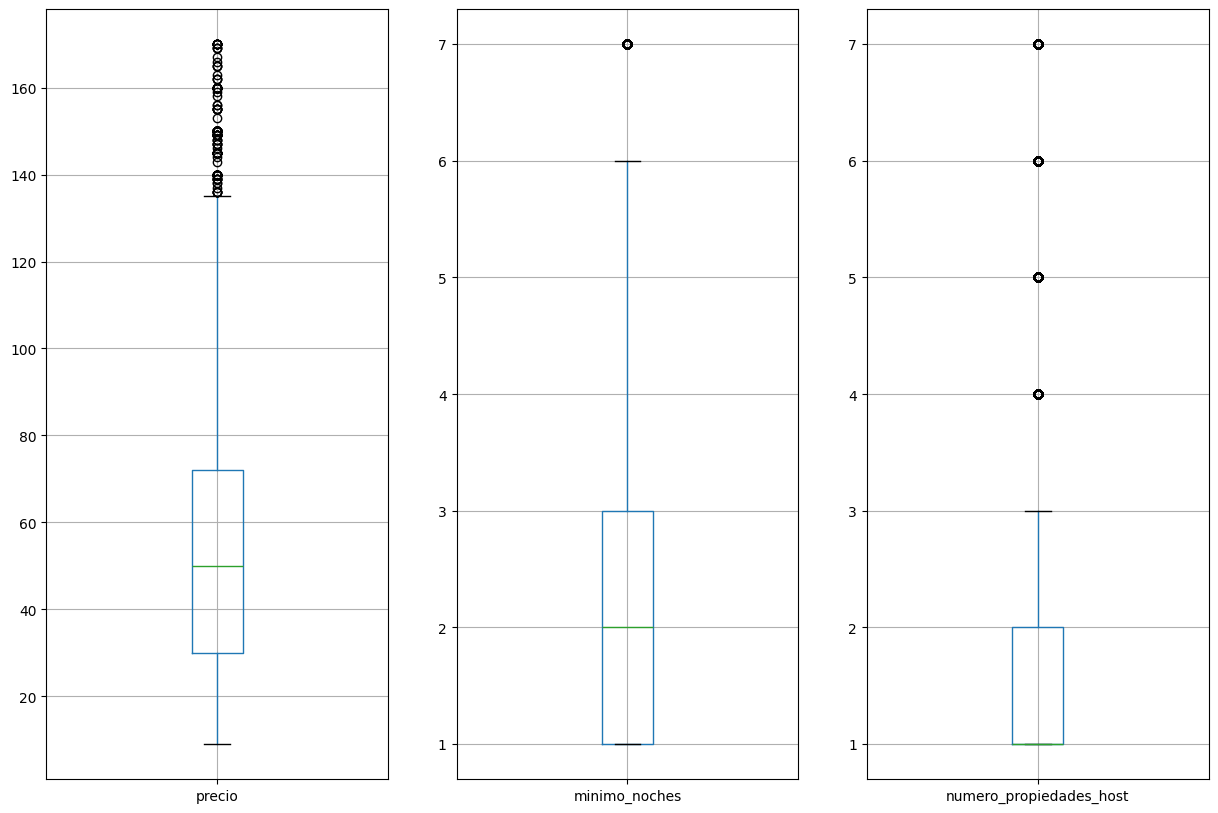

In [ ]:
dataset_train_3_variables_sin_atipicos = dataset_train_3_variables[
	(z_score_modif_mayor['minimo_noches'] != True) & 
	(z_score_modif_mayor['numero_propiedades_host'] != True) & 
	(z_score_modif_mayor['precio'] != True)
]

_, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 10))

dataset_train_3_variables_sin_atipicos.boxplot(column='precio', ax=axes[0])
dataset_train_3_variables_sin_atipicos.boxplot(column='minimo_noches', ax=axes[1])
dataset_train_3_variables_sin_atipicos.boxplot(column='numero_propiedades_host', ax=axes[2])

print(dataset_train_3_variables_sin_atipicos.shape)

plt.show()

Las características `minimo_noches` y `numero_propiedades_host` no tienen mucha correlación con el precio, según se puede observar en la matriz de correlaciones, por lo que intuitivamente se podría optar por eliminar el mayor número de valores atípicos. Sin embargo, se eliminarían también los valores de las otras características de la instancia, pudiéndose perder más información de la pretendida.

In [33]:
dataset_train_3_variables.corr()

,precio,minimo_noches,numero_propiedades_host
precio,1.000000,0.029186,0.103048
minimo_noches,0.029186,1.000000,0.048142
numero_propiedades_host,0.103048,0.048142,1.000000


Por esto, y junto con la consideración realizada arriba sobre la distribución, se optará por eliminar los valores atípicos en base al z-score.

Para ello, a partir de `dataset_train`, se escogerán las instancias que tenían el $|Z_i|$ menor a 3 para las tres características. El índice de estos datos se encuentran en la variable `conjunto_z_score_mayor`.

In [ ]:
dataset_train_sin_atipicos = dataset_train[
	(z_score_mayor['minimo_noches'] != True) & 
	(z_score_mayor['numero_propiedades_host'] != True) & 
	(z_score_mayor['precio'] != True)
]

print(dataset_train_sin_atipicos.shape)

(10138, 12)


A partir de aquí, el conjunto de entrenamiento será `dataset_train_sin_atipicos`, pero el de test será el mismo, `dataset_test`. El preprocesado que se aplicará sobre cada características será el mismo que se ha definido en el problema de clasificación.

In [ ]:
tipo_habitacion_columna = ['tipo_habitacion']
org_territorial_columnas = ['distrito', 'barrio']
coordenadas_columnas = ['latitud', 'longitud']
disponibilidad_columnas = ['disponibilidad_anual']
opiniones_columnas = ['numero_opiniones', 'opiniones_mes']
log_columnas = ['minimo_noches', 'numero_propiedades_host']
precio_columna = ['precio']

class TransformadorCoordenadas(BaseEstimator, TransformerMixin):
	# def __init__(self):

	def transform(self, X : pd.DataFrame):
		'''
		Se tomará como primera columna la latitud y la segunda columna la longitud
		'''
		if isinstance(X, pd.DataFrame):
			X = X.to_numpy()
		
		dimensiones = X.shape
		if dimensiones[1] != 2:
			raise ValueError('Los datos no disponen de dos columnas')

		# Matriz para las coordenadas x, y, z
		coordenadas_transformadas = np.ndarray(shape=(dimensiones[0], 3), dtype=float)

		for fila in range(0, dimensiones[0]):
			coordenadas_transformadas[fila] = [
				np.cos(np.deg2rad(X[fila, 0])) * np.cos(np.deg2rad(X[fila, 1])),
				np.cos(np.deg2rad(X[fila, 0])) * np.sin(np.deg2rad(X[fila, 1])),
				np.sin(np.deg2rad(X[fila, 0]))
			]
		
		return coordenadas_transformadas

	def fit(self, X, y=None):
		'''
		No hace nada porque la transformación se realiza utilizando un algoritmo
		que no requiere de datos anteriores
		'''
		return self


	def get_feature_names_out(self, names=None):
		return ['x', 'y', 'z']

habitacion_pipeline = make_pipeline(
	OrdinalEncoder()
)

org_territorial_pipeline = make_pipeline(
	BinaryEncoder()
)

coordenadas_pipeline = make_pipeline(
	TransformadorCoordenadas()
)

disponibilidad_pipeline = make_pipeline(
	KBinsDiscretizer(
		n_bins = 4, encode='onehot-dense', 
		strategy='quantile', quantile_method='linear', random_state=0
	)
)

opiniones_pipeline = make_pipeline(
	FunctionTransformer(np.sqrt, feature_names_out="one-to-one"),
	RobustScaler()
)

log_pipeline = make_pipeline(
	FunctionTransformer(np.log, feature_names_out="one-to-one"),
	RobustScaler()
)

precio_pipeline = make_pipeline(
	FunctionTransformer(np.log, feature_names_out="one-to-one"),
	StandardScaler()
)

transformador_habitacion 		= (habitacion_pipeline, tipo_habitacion_columna)
transformador_barrio_distrito 	= (org_territorial_pipeline, org_territorial_columnas)
transformador_coordenadas 		= (coordenadas_pipeline, coordenadas_columnas)
transformador_disponibilidad 	= (disponibilidad_pipeline, disponibilidad_columnas)
transformador_opiniones 		= (opiniones_pipeline, opiniones_columnas)
transformador_log 				= (log_pipeline, log_columnas)
transformador_precio 			= (precio_pipeline, precio_columna)

En este caso, como la salida del modelo debe ser el precio, los pipelines sí que difieren.

In [ ]:
# Pipeline completo

# Para los datos de entrada
preprocesamiento_reg = make_column_transformer(
	transformador_barrio_distrito,
	transformador_habitacion,	# el pipeline para la habitación pasa aquí
	transformador_coordenadas,
	transformador_opiniones,
	transformador_log,
	transformador_disponibilidad,
	# Para mantener los nombres de las características
	verbose_feature_names_out=False
)

# Para los datos de salida
preprocesamiento_target_reg = make_column_transformer(
	transformador_precio,		# el del precio pasa aquí.
	# Para mantener el nombre de la característica
	verbose_feature_names_out=False
)

Se ajustan los escaladores y se obtiene los datos de entrada y salida para el entrenamiento del modelo.

In [57]:
dataset_procesado = preprocesamiento_reg.fit_transform(dataset_train_sin_atipicos)
x_train = pd.DataFrame(data=dataset_procesado, columns=preprocesamiento_reg.get_feature_names_out())

dataset_procesado = preprocesamiento_target_reg.fit_transform(dataset_train_sin_atipicos)
y_train = pd.DataFrame(data=dataset_procesado, columns=preprocesamiento_target_reg.get_feature_names_out())

Definimos una función parecida a `generar_x_y` solo que con los nuevos pipelines. Con esta función obtendremos la división del conjunto de test.

In [ ]:
def generar_x_y_reg(datos):
	'''
	Divide los datos en los conjuntos X e Y, ya preprocesados, para su uso en los
	modelos.
	'''
	x = pd.DataFrame(
		data = preprocesamiento_reg.transform(datos), 
		columns = preprocesamiento_reg.get_feature_names_out()
	)

	y = pd.DataFrame(
		data = preprocesamiento_target_reg.transform(datos), 
		columns = preprocesamiento_target_reg.get_feature_names_out()
	)

	return x,y

x_test, y_test = generar_x_y_reg(dataset_test)

c:\Users\mansu\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


#### Validación y entrenamiento de los modelos

En el enunciado de la práctica se indica que para la cross-validation se pruebe con todas las características excepto las correspondientes al barrio.

In [66]:
columnas_sin_barrio = [columna for columna in x_train.columns if columna.startswith('barrio')]

x_train_sin_barrio = x_train.drop(columns=columnas_sin_barrio)

x_train_sin_barrio.columns

Index(['distrito_0', 'distrito_1', 'distrito_2', 'distrito_3', 'distrito_4',
       'tipo_habitacion', 'x', 'y', 'z', 'numero_opiniones', 'opiniones_mes',
       'minimo_noches', 'numero_propiedades_host', 'disponibilidad_anual_0.0',
       'disponibilidad_anual_1.0', 'disponibilidad_anual_2.0',
       'disponibilidad_anual_3.0'],
      dtype='object')

Realizamos la cross-validation para los dos modelos. Como no se define que scoring utilizar, debido a la existencia de los valores atípicos, se va a optar por usar el negativo del error medio absoluto. De esta forma el error generado por estos valores no provocará que una gran penalización comparado con el error cuadrático medio.

In [ ]:
resetear_semilla()

modelo_svr = SVR()

cross_val_svr = cross_val_score(
	modelo_svr, x_train_sin_barrio, y_train.to_numpy().ravel(), cv=10, scoring='neg_mean_absolute_error'
)

In [ ]:
resetear_semilla()

modelo_linear_svr = LinearSVR(random_state=0)

cross_val_linear_svr = cross_val_score(
	modelo_linear_svr, x_train_sin_barrio, y_train.to_numpy().ravel(), cv=10, scoring='neg_mean_absolute_error'
)

Si revisamos el error medio cometido, vemos como para el SVR se tiene un error medio de -0.47 mientras que para el LinearSVR se tiene -0.51. Se escoge, por tanto, el SVR, pues al ser el negativo, a mayor error, mejor modelo.

In [74]:
print(cross_val_svr.mean(), cross_val_linear_svr.mean())

-0.47962300116128065 -0.5150990723551898


Se puede comprobar el impacto del barrio si realizamos de nuevo el entrenamiento del mejor modelo añadiendo la característica

In [ ]:
resetear_semilla()

modelo_svr = SVR()

cross_val_svr = cross_val_score(
	modelo_svr, x_train, y_train.to_numpy().ravel(), cv=10, scoring='neg_mean_absolute_error'
)

cross_val_svr.mean()

np.float64(-0.4646130461634268)

El error no ha disminuido de forma considerable por lo que se va a mantener los datos sin el barrio.

Para el afinamiento de los hiperparámetros se tomarán los mismos intervalos tomados en el problema de clasificación.

In [ ]:
resetear_semilla()

pipeline_svr = Pipeline([
	("svr", SVR())
])

min_exp_C = -5
max_exp_C = 10

min_exp_gamma = -10
max_exp_gamma = 3

parametros_svr = {
	# Se calcularán tantos valores como exponentes enteros haya entre min_exp_C y max_exp_C
	'svr__C' : np.logspace(
		start=min_exp_C, stop=max_exp_C, base=2, num=len(list(range(min_exp_C,max_exp_C+1)))
	),
	# Se calcularán tantos valores como exponentes enteros haya entre min_exp_C y max_exp_C
	'svr__gamma' : np.logspace(
		start=min_exp_gamma, stop=max_exp_gamma, base=2, num=len(list(range(min_exp_gamma,max_exp_gamma+1)))
	)
}

optimizacion_svr = GridSearchCV(
	pipeline_svr, 
	parametros_svr, 
	cv=10, 
	scoring="neg_mean_absolute_error",
	n_jobs=6
)

optimizacion_svr.fit(x_train_sin_barrio, y_train.to_numpy().ravel())

,estimator,"Pipeline(step...svr', SVR())])"
,param_grid,"{'svr__C': array([3.125e...2, 1.024e+03]), 'svr__gamma': array([9.7656...8.000000e+00])}"
,scoring,'neg_mean_absolute_error'
,n_jobs,6
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,kernel,'rbf'


In [79]:
joblib.dump(optimizacion_svr.best_estimator_, 'primera_estimacion_svr.pkl')

['primera_estimacion_svr.pkl']

Los mejores parámetros han sido $C=1$ y $\gamma = 0.25$. Realizamos la segunda búsqueda acotando el intervalo de búsqueda de los hiperparámetros, decrementando 3 a partir del valor óptimo y seleccionando solo 7 elementos de ese intervalo (debido al tiempo que ha tardado en realizar la primera búsqueda).

In [82]:
optimizacion_svr.best_params_

{'svr__C': np.float64(1.0), 'svr__gamma': np.float64(0.25)}

In [ ]:
resetear_semilla()

pipeline_svr = Pipeline([
	("svr", SVR())
])

mejor_exp_C = 0
var_exp_C = 3

mejor_exp_gamma = -4
var_exp_gamma = 3

parametros_svr = {
	# Se calcularán tantos valores como exponentes enteros haya entre min_exp_C y max_exp_C
	'svr__C' : np.logspace(
		start=(mejor_exp_C - var_exp_C), stop=(mejor_exp_C + var_exp_C), base=2, num=7
	),
	# Se calcularán tantos valores como exponentes enteros haya entre min_exp_C y max_exp_C
	'svr__gamma' : np.logspace(
		start=(mejor_exp_gamma - var_exp_gamma), stop=(mejor_exp_gamma + var_exp_gamma), base=2, num=7
	)
}

optimizacion_svr_segunda = GridSearchCV(
	pipeline_svr, 
	parametros_svr, 
	cv=10, 
	scoring="neg_mean_absolute_error",
	n_jobs=6
)

optimizacion_svr_segunda.fit(x_train_sin_barrio, y_train.to_numpy().ravel())

,estimator,"Pipeline(step...svr', SVR())])"
,param_grid,"{'svr__C': array([0.125,...4. , 8. ]), 'svr__gamma': array([0.0078... 0.5 ])}"
,scoring,'neg_mean_absolute_error'
,n_jobs,6
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,kernel,'rbf'


Tras hacer las segunda búsqueda, los mejores valores vuelven a ser los encontrados en la primera búsqueda.

In [84]:
optimizacion_svr_segunda.best_params_

{'svr__C': np.float64(1.0), 'svr__gamma': np.float64(0.25)}

In [85]:
# joblib.dump(optimizacion_svr_segunda.best_estimator_, 'modelo_svr.pkl')
# mejor_modelo_svr = joblib.load('modelo_svr.pkl')

['modelo_svr.pkl']

Calculamos el error de porcentaje medio absoluto (MAPE) del conjunto de test, para no tener que basarnos en la escala de los datos para identificar el error del modelo. Primero hay que eliminar las columnas correspondientes al barrio.

In [129]:
x_test_sin_barrio = x_test.drop(columns=columnas_sin_barrio)

y_predicho_svr = optimizacion_svr_segunda.best_estimator_.predict(x_test_sin_barrio)

Esta predicción es necesario aplicarle el proceso inverso de la transformación realizada. Se puede acceder al pipeline de `preprocesamiento_target_reg` mediante la clave `pipeline`. A través de ese pipeline se puede ejecutar el método `inverse_transform`, aunque solo ejecutará la transformación inversa del escalador, por lo que habrá que usar $e$ para obtener el valor real.

In [131]:
y_test

,precio
0,-0.360687
1,-0.009009
2,-2.015221
3,-0.867507
4,-0.175059
...,...
2659,0.278332
2660,-1.709228
2661,-0.980127
2662,-1.101419


In [132]:
y_test_original = np.e ** preprocesamiento_target_reg['pipeline'].inverse_transform(y_test)
y_pred_original = np.e ** preprocesamiento_target_reg['pipeline'].inverse_transform(pd.DataFrame(y_predicho_svr, columns=['precio']))

In [139]:
mape_svr = mean_absolute_percentage_error(y_test_original, y_pred_original)
mape_svr * 100

30.55421104664921

###
---

### Conclusiones

#### Problema de clasificación

Al realizar la cross-validation al comienzo del planteamiento del problema, para el modelo SVC, que por defecto usa la pérdida de Hinge y tiene como kernel funciones RBF gausianas, obtiene una exactitud media del $\approx 90\%$, mientras que el modelo LinearSVC, que usa la pérdida cudadrada de Hinge y tiene como kernel una función lineal, obtiene una exactitud media de $\approx 87\%$. Esto, a priori, indica que la distribución de los datos no es tan lineal, aún cuando se pueden diferenciar con una buena exactitud usando un modelo lineal.

In [28]:
print(cross_val_svc.mean(), cross_val_linear_svc.mean())

0.9024124232574937 0.8773573272027411


Si observamos los datos del conjunto de test, primero del modelo lineal, podemos ver que se mantiene al mismo porcentaje que el obtenido como media en la cross-validation.

In [35]:
exactitud_linear_svc_test

0.8795045045045045

Concretamente, la clasificación realizada por el modelo lineal, en comparación con la clase original de los datos, es la siguiente:

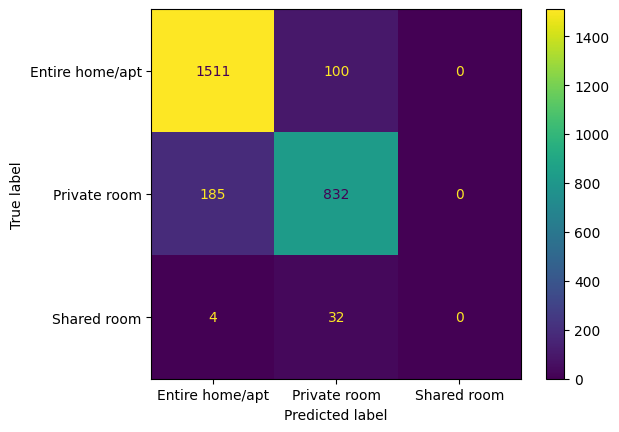

In [ ]:
matriz_confusion = confusion_matrix(y_test, y_predicho_linear_svc)

matriz_confusion_grafica = ConfusionMatrixDisplay(
	matriz_confusion, display_labels=dataset['tipo_habitacion'].unique())

matriz_confusion_grafica.plot()
plt.show()

Podemos ver como el modelo ha sido incapaz de predecir correctamente las instancias que eran de tipo habitación compartida, confundiéndolas en su mayoría con habitaciones privadas. Sin embargo, para las otras dos clases el modelo desempeña de forma bastante aceptable.

Mientras que para el modelo que usa de kernel las RBF gausianas, con un valor de C de 256 y un valor de $\gamma$ de 0.015625, el porcentaje es bastante parecido al obtenido en la cross-validation.

In [32]:
exactitud_svc_test

0.9016516516516516

Observando de nuevo la matriz de confusión con las predicciones realizadas por este modelos:

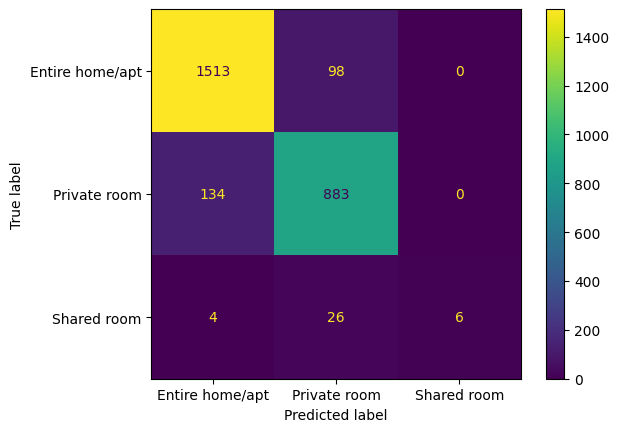

In [ ]:
matriz_confusion = confusion_matrix(y_test, y_predicho_svc)

matriz_confusion_grafica = ConfusionMatrixDisplay(
	matriz_confusion, display_labels=dataset['tipo_habitacion'].unique())

matriz_confusion_grafica.plot()
plt.show()

En este caso el modelos, al ser más complejo, pues está usando un kernel de RBF gausianas en lugar de solo un kernel lineal, es capaz de clasificar ligeramente mejor las clases de habitación privada y de apartamento completo. Para la clase de habitación compartida, aún comentiendo muchos fallos al igual que el modelo lineal, al menos en algunas ocasiones es capaz de acertar.

#### Problema de regresión

Para este problema, tras eliminar un subconjunto de los valores atípicos para el entrenamiento, los valores para el MAE en la cross-validation de los modelos SVR y LinearSVR ha quedado 0.479 y 0.515. Tiene sentido que sea el SVR el que menor error produzca, pues en el problema de clasificación se intuía que los datos no tenían un separación tan lineal.

In [140]:
print(cross_val_svr.mean(), cross_val_linear_svr.mean())

-0.4646130461634268 -0.5150990723551898


Tras la primera afinación de los hiperparámetros $C$ y $\gamma$, los valores óptimos encontrados han sido 1 y 0.25 respectivamente. Tras la segunda afinación acotando más los intervalos de búsqueda se ha concluido que los valores óptimos eran los encontrados anteriormente. En estas dos búsquedas se ha reducido los intervalos debido al tiempo que ha llevado la búsqueda, siendo de casi 3 horas en la primera.

Con el modelo final se ha calculado las predicciones del conjunto de test y con ellas el MAPE. El resultado ha sido de un error del 30%, bastante elevado.

In [143]:
mape_svr * 100

30.55421104664921

Podemos ver un subconjunto de las predicciones hechas por el modelo en la siguiente gráfica. Los puntos celeste son los valores reales, mientras que los de color salmón son los predichos. Podemos ver como par los valores más altos, que probablemente sean valores atípicos, el error cometido es bastante elevado.

(-5.0, 105.0)

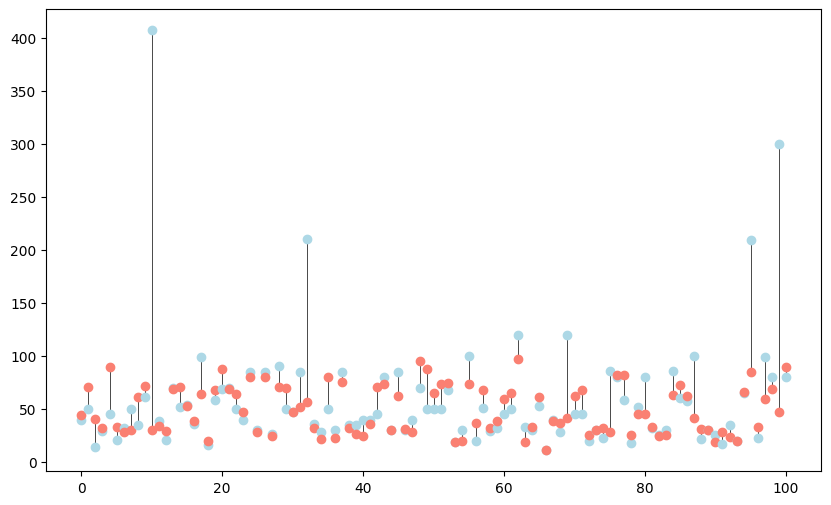

In [244]:
y_test_original_plano = y_test_original.ravel()
y_pred_original_plano = y_pred_original.ravel()

fig, ax = plt.subplots(figsize=(10, 6))

for indice in range(0,101):
	ax.scatter(indice, y_test_original_plano[indice], c='lightblue')
	ax.scatter(indice, y_pred_original_plano[indice], c='salmon')

	ax.plot(
		(indice, indice), 
		(y_test_original_plano[indice], y_pred_original_plano[indice]), 
		c='black', 
		alpha=1, 
		linewidth=0.5,
		zorder=-1
	)

plt.xlim((-5,105))

###
---

### Bibliografía
(están includos los PDFs en el ZIP)

>Osborne, J. W., & Overbay, A. (2004). The power of outliers (and why researchers should always check for them). Practical Assessment, Research, and Evaluation, 9(1).

>Seo, S. (2006). A review and comparison of methods for detecting outliers in univariate data sets (Doctoral dissertation, University of Pittsburgh).